In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_excel('Тестовое_задание_Data_аналитик_ЦО_2025_2.xlsx', sheet_name="Данные для задачи 1", engine="calamine")
data

,Бренд,Код товара,Наименование товара,Категория1,Категория2,Категория3,Категория4,Сегмент,Цена закупки товара,letu.ru,iledebeaute.ru,rivegauche.ru,Ozon,Wildberries,MagnitMarket,Megamarket,lamoda.ru,tsum.ru,visagehall.ru
0,Clarins,19000412437,CLARINS Тушь д/ресниц Wonder volume xxl 8мл,Макияж,Глаза,Тушь для ресниц,NaN,Люкс,983,NaN,1029.0,NaN,NaN,NaN,NaN,NaN,1117.0,NaN,NaN
1,Clarins,14037100013,Clarins Флюид тональный устойчивый с омолажива...,Макияж,Лицо,Тональные основы,Жидкие тональные основы,Люкс,1957,NaN,2107.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Clarins,19000033387,CLARINS Масло-блеск для губ Lip Comfort Oil т....,Макияж,Губы,Масло для губ_макияж,NaN,Люкс,850,NaN,1065.0,919.0,964.0,NaN,NaN,NaN,924.0,1574.0,964.0
3,Clarins,14037100015,Clarins Флюид тональный устойчивый с омолажива...,Макияж,Лицо,Тональные основы,Жидкие тональные основы,Люкс,2145,NaN,2355.0,3536.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Clarins,19000168458,Clarins Масло-блеск д/губ Lip Comfort 17 7мл,Макияж,Губы,Масло для губ_макияж,NaN,Люкс,835,NaN,924.0,1039.0,1045.0,NaN,NaN,NaN,1065.0,1742.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
678,Clarins,19760334992,Clarins Вода мицеллярная д/чувствительной кожи...,Уход,Уход за лицом,Очищение/демакияж,Мицеллярные средства,Люкс,1565,NaN,NaN,NaN,3133.0,NaN,NaN,NaN,NaN,NaN,3084.0
679,Vivienne Sabo,19000023602,Vivienne Sabo Тушь д/ресниц влагостойкая Metam...,Макияж,Глаза,Тушь для ресниц,Тушь,Массмаркет,217,NaN,NaN,NaN,NaN,NaN,NaN,351.0,NaN,NaN,NaN
680,Clarins,15020100006,Кларанс Крем д/лица пенящийся с отшелушивающим...,Уход,Уход за лицом,Очищение/демакияж,Прочее очищение/демакияж,Люкс,1922,NaN,3898.0,4095.0,NaN,NaN,NaN,NaN,3983.0,NaN,NaN
681,Vivienne Sabo,3223400002,Vivienne Sabo Тушь д/ресниц Cabaret Premiere 0...,Макияж,Глаза,Тушь для ресниц,Тушь,Массмаркет,208,334.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
reference_book = pd.read_excel('Тестовое_задание_Data_аналитик_ЦО_2025_2.xlsx', sheet_name="Справочник наценок", engine="calamine")
reference_book

,Сегмент рынка,Категория,Бренд,Продукт,Дата начала,Дата окончания,Наценка,Активный
0,Люкс,NaN,NaN,NaN,2025-01-01,NaT,1.20,Да
1,Массмаркет,NaN,NaN,NaN,2025-01-01,NaT,0.70,Да
2,Люкс,Макияж,NaN,NaN,2025-01-01,NaT,0.90,Да
3,Люкс,Уход,NaN,NaN,2025-01-01,NaT,1.50,Да
4,Массмаркет,Макияж,NaN,NaN,2025-01-01,NaT,0.50,Да
...,...,...,...,...,...,...,...,...
118,NaN,Карандаш для бровей,Vivienne Sabo,NaN,2025-06-01,NaT,0.95,Да
119,NaN,NaN,NaN,1.900022e+10,2025-01-01,NaT,2.50,Да
120,NaN,NaN,NaN,1.900042e+10,2025-01-01,NaT,2.50,Да
121,NaN,NaN,NaN,1.900036e+10,2025-01-01,NaT,2.50,Да


In [4]:
# Дата, на которую проверяется активность правил.
AS_OF_DATE = pd.Timestamp.today().normalize()
# Минимально допустимая валовая маржа
MIN_GM = 0.10

# "markup": цена = закупка * (1 + наценка)
# 'multiplier': цена = закупка * наценка
# По смыслу названия поля «Наценка» основной вариант "markup",
PRICE_FORMULA = "markup"

### Промежуточный вывод: 
- проверяем правила наценки на сегодняшнюю дату
- минимальная маржа - 10%
- цену до скидки считаем как закупка * (1 + наценка)

In [5]:
def clean_text(series):
    return series.astype("string").fillna("").str.strip()

def to_number(series):
    return pd.to_numeric(
        clean_text(series)
        .str.replace("\xa0", "", regex=False)
        .str.replace(" ", "", regex=False)
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

In [6]:
# Текстовые поля товара
product_text_columns = [
    "Бренд", "Код товара", "Наименование товара",
    "Категория1", "Категория2", "Категория3", "Категория4", "Сегмент"
]

for col in product_text_columns:
    data[col] = clean_text(data[col])

# Стоимость и цены конкурентов
cost_col = "Цена закупки товара"
competitors = data.columns[data.columns.get_loc(cost_col) + 1:].tolist()

data[cost_col] = to_number(data[cost_col])
for col in competitors:
    data[col] = to_number(data[col])

# Поля справочника
rule_text_columns = ["Сегмент рынка", "Категория", "Бренд", "Продукт", "Активный"]
for col in rule_text_columns:
    reference_book[col] = clean_text(reference_book[col])

reference_book["Дата начала"] = pd.to_datetime(reference_book["Дата начала"], errors="coerce")
reference_book["Дата окончания"] = pd.to_datetime(reference_book["Дата окончания"], errors="coerce")
reference_book["Наценка"] = to_number(reference_book["Наценка"])

# Номер строки исходного Excel — удобно для проверки выбранного правила
reference_book["excel_row"] = reference_book.index + 2

In [7]:
display(data.head(3))
display(reference_book.head(10))

,Бренд,Код товара,Наименование товара,Категория1,Категория2,Категория3,Категория4,Сегмент,Цена закупки товара,letu.ru,iledebeaute.ru,rivegauche.ru,Ozon,Wildberries,MagnitMarket,Megamarket,lamoda.ru,tsum.ru,visagehall.ru
0,Clarins,19000412437,CLARINS Тушь д/ресниц Wonder volume xxl 8мл,Макияж,Глаза,Тушь для ресниц,,Люкс,983,<NA>,1029.0,<NA>,<NA>,<NA>,<NA>,<NA>,1117.0,<NA>,<NA>
1,Clarins,14037100013,Clarins Флюид тональный устойчивый с омолажива...,Макияж,Лицо,Тональные основы,Жидкие тональные основы,Люкс,1957,<NA>,2107.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,Clarins,19000033387,CLARINS Масло-блеск для губ Lip Comfort Oil т....,Макияж,Губы,Масло для губ_макияж,,Люкс,850,<NA>,1065.0,919.0,964.0,<NA>,<NA>,<NA>,924.0,1574.0,964.0


,Сегмент рынка,Категория,Бренд,Продукт,Дата начала,Дата окончания,Наценка,Активный,excel_row
0,Люкс,,,,2025-01-01,NaT,1.2,Да,2
1,Массмаркет,,,,2025-01-01,NaT,0.7,Да,3
2,Люкс,Макияж,,,2025-01-01,NaT,0.9,Да,4
3,Люкс,Уход,,,2025-01-01,NaT,1.5,Да,5
4,Массмаркет,Макияж,,,2025-01-01,NaT,0.5,Да,6
5,Массмаркет,Уход,,,2025-01-01,NaT,0.85,Да,7
6,Массмаркет,Брови,,,2025-01-01,NaT,1.1,Да,8
7,,Авто загар,Clarins,,2025-01-01,NaT,1.07,Да,9
8,,Аксессуары_уход,Clarins,,2025-01-01,NaT,1.19,Да,10
9,,Антицеллюлитная серия/коррекция фигуры,Clarins,,2025-01-01,NaT,0.86,Да,11


### Промежуточный вывод: данные
- в анализе 683 товара двух брендов: Clarins (442) и Vivienne Sabo (241)
- цены есть у 10 конкурентов
- справочник наценок содержит 123 правила, данные приведены к единому формату

In [8]:
# Фильтрация действующих правил и контроль качества справочника
reference_book["is_active"] = reference_book["Активный"].str.casefold().eq("да")

# Дата окончания считается включительной:
# правило работает, пока AS_OF_DATE <= Дата окончания.
reference_book["is_valid_on_date"] = (
    reference_book["Дата начала"].notna()
    & (reference_book["Дата начала"] <= AS_OF_DATE)
    & (
        reference_book["Дата окончания"].isna()
        | (AS_OF_DATE <= reference_book["Дата окончания"])
    ))

valid_rules = reference_book.loc[reference_book["is_active"] & reference_book["is_valid_on_date"] & reference_book["Наценка"].notna()].copy()

print(f"Действующих правил на {AS_OF_DATE.date()}: {len(valid_rules)}")
print(f"Неактивных правил: {(~reference_book['is_active']).sum()}")
print(f"Правил вне срока действия: {(~reference_book['is_valid_on_date']).sum()}")

Действующих правил на 2026-10-29: 120
Неактивных правил: 3
Правил вне срока действия: 2


In [9]:
# Контроль: у товарного правила не должно быть дополнительно заполненных условий
mixed_product_rules = valid_rules.loc[
    (valid_rules["Продукт"] != "")
    & (
        (valid_rules["Бренд"] != "")
        | (valid_rules["Категория"] != "")
        | (valid_rules["Сегмент рынка"] != "")
    )]
if len(mixed_product_rules):
    print("Внимание: найдены товарные правила с дополнительными условиями.")
    display(mixed_product_rules)

### Промежуточный вывод: справочник наценок
- действующими остались 120 правил из 123
- 3 правила отброшены: они неактивны или у них истёк срок
- товарных правил с лишними условиями нет, так что путаницы с приоритетами не будет

In [10]:
# Приоритетный выбор правила наценки
def choose_rule(product_row, rule_df):
    """
    Возвращает правило с максимальным приоритетом.
    Если на одном уровне несколько действующих совпадений,
    наценка не выбирается автоматически — строка помечается как конфликт.
    """
    brand = product_row["Бренд"]
    segment = product_row["Сегмент"]
    category1 = product_row["Категория1"]
    category2 = product_row["Категория2"]
    category3 = product_row["Категория3"]
    sku = product_row["Код товара"]

    blank_brand = rule_df["Бренд"].eq("")
    blank_segment = rule_df["Сегмент рынка"].eq("")
    blank_category = rule_df["Категория"].eq("")
    blank_product = rule_df["Продукт"].eq("")

    priorities = [
        (
            "Продукт",
            rule_df["Продукт"].eq(sku)
        ),
        (
            "Бренд / Категория3",
            (category3 != "")
            & rule_df["Бренд"].eq(brand)
            & rule_df["Категория"].eq(category3)
            & blank_segment
            & blank_product
        ),
        (
            "Бренд / Категория2",
            (category2 != "")
            & rule_df["Бренд"].eq(brand)
            & rule_df["Категория"].eq(category2)
            & blank_segment
            & blank_product
        ),
        (
            "Бренд / Категория1",
            (category1 != "")
            & rule_df["Бренд"].eq(brand)
            & rule_df["Категория"].eq(category1)
            & blank_segment
            & blank_product
        ),
        (
            "Бренд",
            rule_df["Бренд"].eq(brand)
            & blank_segment
            & blank_category
            & blank_product
        ),
        (
            "Сегмент / Категория3",
            (category3 != "")
            & rule_df["Сегмент рынка"].eq(segment)
            & rule_df["Категория"].eq(category3)
            & blank_brand
            & blank_product
        ),
        (
            "Сегмент / Категория2",
            (category2 != "")
            & rule_df["Сегмент рынка"].eq(segment)
            & rule_df["Категория"].eq(category2)
            & blank_brand
            & blank_product
        ),
        (
            "Сегмент / Категория1",
            (category1 != "")
            & rule_df["Сегмент рынка"].eq(segment)
            & rule_df["Категория"].eq(category1)
            & blank_brand
            & blank_product
        ),
        (
            "Сегмент",
            rule_df["Сегмент рынка"].eq(segment)
            & blank_brand
            & blank_category
            & blank_product
        ),
    ]
    for priority_num, (priority_name, mask) in enumerate(priorities, start=1):
        matches = rule_df.loc[mask]

        if len(matches) == 1:
            rule = matches.iloc[0]
            return {
                "priority_num": priority_num,
                "priority_name": priority_name,
                "rule_excel_row": rule["excel_row"],
                "selected_markup": rule["Наценка"],
                "rule_conflict": False,
                "matching_rules_count": 1,
            }
        if len(matches) > 1:
            return {
                "priority_num": priority_num,
                "priority_name": priority_name,
                "rule_excel_row": pd.NA,
                "selected_markup": np.nan,
                "rule_conflict": True,
                "matching_rules_count": len(matches),
            }
    return {
        "priority_num": pd.NA,
        "priority_name": "Нет подходящего правила",
        "rule_excel_row": pd.NA,
        "selected_markup": np.nan,
        "rule_conflict": False,
        "matching_rules_count": 0,
    }
rule_selection = data.apply(lambda row: pd.Series(choose_rule(row, valid_rules)), axis=1)

In [11]:
data = pd.concat([data, rule_selection], axis=1)
data

,Бренд,Код товара,Наименование товара,Категория1,Категория2,Категория3,Категория4,Сегмент,Цена закупки товара,letu.ru,...,Megamarket,lamoda.ru,tsum.ru,visagehall.ru,priority_num,priority_name,rule_excel_row,selected_markup,rule_conflict,matching_rules_count
0,Clarins,19000412437,CLARINS Тушь д/ресниц Wonder volume xxl 8мл,Макияж,Глаза,Тушь для ресниц,,Люкс,983,<NA>,...,<NA>,1117.0,<NA>,<NA>,5,Бренд,51,1.03,False,1
1,Clarins,14037100013,Clarins Флюид тональный устойчивый с омолажива...,Макияж,Лицо,Тональные основы,Жидкие тональные основы,Люкс,1957,<NA>,...,<NA>,<NA>,<NA>,<NA>,5,Бренд,51,1.03,False,1
2,Clarins,19000033387,CLARINS Масло-блеск для губ Lip Comfort Oil т....,Макияж,Губы,Масло для губ_макияж,,Люкс,850,<NA>,...,<NA>,924.0,1574.0,964.0,5,Бренд,51,1.03,False,1
3,Clarins,14037100015,Clarins Флюид тональный устойчивый с омолажива...,Макияж,Лицо,Тональные основы,Жидкие тональные основы,Люкс,2145,<NA>,...,<NA>,<NA>,<NA>,<NA>,5,Бренд,51,1.03,False,1
4,Clarins,19000168458,Clarins Масло-блеск д/губ Lip Comfort 17 7мл,Макияж,Губы,Масло для губ_макияж,,Люкс,835,<NA>,...,<NA>,1065.0,1742.0,<NA>,5,Бренд,51,1.03,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
678,Clarins,19760334992,Clarins Вода мицеллярная д/чувствительной кожи...,Уход,Уход за лицом,Очищение/демакияж,Мицеллярные средства,Люкс,1565,<NA>,...,<NA>,<NA>,<NA>,3084.0,5,Бренд,51,1.03,False,1
679,Vivienne Sabo,19000023602,Vivienne Sabo Тушь д/ресниц влагостойкая Metam...,Макияж,Глаза,Тушь для ресниц,Тушь,Массмаркет,217,<NA>,...,351.0,<NA>,<NA>,<NA>,2,Бренд / Категория3,102,0.41,False,1
680,Clarins,15020100006,Кларанс Крем д/лица пенящийся с отшелушивающим...,Уход,Уход за лицом,Очищение/демакияж,Прочее очищение/демакияж,Люкс,1922,<NA>,...,<NA>,3983.0,<NA>,<NA>,5,Бренд,51,1.03,False,1
681,Vivienne Sabo,3223400002,Vivienne Sabo Тушь д/ресниц Cabaret Premiere 0...,Макияж,Глаза,Тушь для ресниц,Тушь,Массмаркет,208,334.0,...,<NA>,<NA>,<NA>,<NA>,2,Бренд / Категория3,102,0.41,False,1


In [12]:
print("Товары без подходящего правила:", data["selected_markup"].isna().sum())
print("Конфликты правил:", data["rule_conflict"].sum())

display(data[[
        "Код товара", "Наименование товара", "Бренд", "Сегмент",
        "Категория1", "Категория2", "Категория3",
        "priority_name", "rule_excel_row",
        "selected_markup", "rule_conflict"
]].head(15))

Товары без подходящего правила: 0
Конфликты правил: 0


,Код товара,Наименование товара,Бренд,Сегмент,Категория1,Категория2,Категория3,priority_name,rule_excel_row,selected_markup,rule_conflict
0,19000412437,CLARINS Тушь д/ресниц Wonder volume xxl 8мл,Clarins,Люкс,Макияж,Глаза,Тушь для ресниц,Бренд,51,1.03,False
1,14037100013,Clarins Флюид тональный устойчивый с омолажива...,Clarins,Люкс,Макияж,Лицо,Тональные основы,Бренд,51,1.03,False
2,19000033387,CLARINS Масло-блеск для губ Lip Comfort Oil т....,Clarins,Люкс,Макияж,Губы,Масло для губ_макияж,Бренд,51,1.03,False
3,14037100015,Clarins Флюид тональный устойчивый с омолажива...,Clarins,Люкс,Макияж,Лицо,Тональные основы,Бренд,51,1.03,False
4,19000168458,Clarins Масло-блеск д/губ Lip Comfort 17 7мл,Clarins,Люкс,Макияж,Губы,Масло для губ_макияж,Бренд,51,1.03,False
5,19000430971,CLARINS Масло-блеск д/губ 54 7мл,Clarins,Люкс,Макияж,Губы,Масло для губ_макияж,Бренд,51,1.03,False
6,19000283309,Clarins Тушь д/ресниц Wonder Volume XXL 01 8мл,Clarins,Люкс,Макияж,Глаза,Тушь для ресниц,Бренд,51,1.03,False
7,19000347411,CLARINS Консилер д/лица Instant 02.5 15мл,Clarins,Люкс,Макияж,Лицо,Корректор/консилер,Бренд / Категория3,35,1.10,False
8,14037100011,Clarins Флюид тональный устойчивый с омолажива...,Clarins,Люкс,Макияж,Лицо,Тональные основы,Бренд,51,1.03,False
9,19000033383,CLARINS Масло-блеск для губ Lip Comfort Oil т....,Clarins,Люкс,Макияж,Губы,Масло для губ_макияж,Бренд,51,1.03,False


### Промежуточный вывод: подбор наценки
- наценка найдена для всех 683 товаров, конфликтов между правилами нет
- чаще всего сработало правило на уровне бренда (381 товар)
- затем бренд/категория3 (275 товаров) и бренд/категория2 (27 товаров)
- правила на уровне продукта и сегмента не понадобились

In [13]:
# Расчёт цены до скидки
if PRICE_FORMULA == "markup":
    data["price_before_discount"] = data[cost_col] * (1 + data["selected_markup"])
elif PRICE_FORMULA == "multiplier":
    data["price_before_discount"] = data[cost_col] * data["selected_markup"]
else:
    raise ValueError("PRICE_FORMULA должен быть 'markup' или 'multiplier'")

data["min_price_gm10"] = data[cost_col] / (1 - MIN_GM)

In [14]:
data[["Код товара", "Наименование товара", cost_col,
    "selected_markup", "price_before_discount", "min_price_gm10"
]].head(10).style.format({
    cost_col: "{:,.0f}",
    "selected_markup": "{:.2f}",
    "price_before_discount": "{:,.0f}",
    "min_price_gm10": "{:,.0f}",
})

,Код товара,Наименование товара,Цена закупки товара,selected_markup,price_before_discount,min_price_gm10
0,19000412437,CLARINS Тушь д/ресниц Wonder volume xxl 8мл,983,1.03,"1,995","1,092"
1,14037100013,Clarins Флюид тональный устойчивый с омолаживающим действием 30мл 108.5W,"1,957",1.03,"3,973","2,174"
2,19000033387,CLARINS Масло-блеск для губ Lip Comfort Oil т.10 7 мл,850,1.03,"1,726",944
3,14037100015,Clarins Флюид тональный устойчивый с омолаживающим действием SPF15 Everlasting Youth Fluid 110 30мл,"2,145",1.03,"4,354","2,383"
4,19000168458,Clarins Масло-блеск д/губ Lip Comfort 17 7мл,835,1.03,"1,695",928
5,19000430971,CLARINS Масло-блеск д/губ 54 7мл,898,1.03,"1,823",998
6,19000283309,Clarins Тушь д/ресниц Wonder Volume XXL 01 8мл,983,1.03,"1,995","1,092"
7,19000347411,CLARINS Консилер д/лица Instant 02.5 15мл,"1,340",1.10,"2,814","1,489"
8,14037100011,Clarins Флюид тональный устойчивый с омолаживающим действием SPF15 Everlasting Youth Fluid 108 30мл,"3,458",1.03,"7,020","3,842"
9,19000033383,CLARINS Масло-блеск для губ Lip Comfort Oil т.04 7 мл,961,1.03,"1,951","1,068"


### Промежуточный вывод: цена до скидки
- цена до скидки посчитана по выбранной наценке
- отдельно посчитана минимальная цена, при которой маржа равна 10%: закупка / 0,9
- у всех товаров цена до скидки выше этого порога

In [15]:
# Индексы цен по конкурентам
market_long = data.melt(
    id_vars=[
        "Код товара", "Наименование товара", "Бренд", "Сегмент",
        cost_col, "price_before_discount", "min_price_gm10"
    ],
    value_vars=competitors,
    var_name="competitor",
    value_name="competitor_price"
)

market_long = market_long.loc[
    market_long["competitor_price"].notna()
    & (market_long["competitor_price"] > 0)
    & market_long["price_before_discount"].notna()
].copy()

market_long["price_index_before_discount"] = market_long["price_before_discount"] / market_long["competitor_price"] * 100

price_index_summary = (
    market_long.groupby("competitor", as_index=False).agg(
        compared_sku=("Код товара", "nunique"),
        mean_price_index=("price_index_before_discount", "mean"),
        median_price_index=("price_index_before_discount", "median"),
        min_price_index=("price_index_before_discount", "min"),
        max_price_index=("price_index_before_discount", "max"),
    ).sort_values("mean_price_index")
)

In [16]:
price_index_summary.style.format({
    "mean_price_index": "{:.1f}",
    "median_price_index": "{:.1f}",
    "min_price_index": "{:.1f}",
    "max_price_index": "{:.1f}",
})

,competitor,compared_sku,mean_price_index,median_price_index,min_price_index,max_price_index
8,tsum.ru,226,100.3,100.4,72.2,119.8
6,letu.ru,193,118.6,110.1,51.4,222.2
1,Megamarket,89,119.3,116.8,74.3,222.2
5,lamoda.ru,364,121.6,118.2,81.4,211.6
0,MagnitMarket,120,121.6,112.5,88.7,209.8
9,visagehall.ru,388,122.1,118.4,88.7,338.0
7,rivegauche.ru,610,122.2,117.6,91.6,216.3
4,iledebeaute.ru,495,127.1,116.4,59.7,643.1
3,Wildberries,176,129.6,128.6,37.2,248.4
2,Ozon,471,131.5,122.8,39.5,344.0


### Промежуточный вывод: индекс цен по конкурентам
- индекс = наша цена до скидки / цена конкурента * 100, выше 100 значит мы дороже
- только с tsum.ru мы на одном уровне (100,3)
- у остальных конкурентов мы дороже на 19–32%
- сильнее всего разрыв с Ozon (131,5) и Wildberries (129,6)
- дальше всего мы от конкурентов по цене на товарах Vivienne Sabo: медианно мы дороже минимума рынка на 54%, у Clarins на 23%

In [17]:
# Рекомендованная цена, скидка и проверка маржинальности
data["market_min_price"] = data[competitors].min(axis=1, skipna=True)
data.loc[data[competitors].isna().all(axis=1), "market_min_price"] = np.nan

# Если мы уже дешевле рынка, скидка не нужна. Сохраняем текущую рассчитанную цену до скидки.
data["competitive_target_price"] = data[
    ["price_before_discount", "market_min_price"]
].min(axis=1, skipna=True)

data.loc[data["market_min_price"].isna(), "competitive_target_price"] = np.nan

data["pricing_status"] = np.select(
    [
        data["selected_markup"].isna(),
        data["market_min_price"].isna(),
        data["price_before_discount"] < data["min_price_gm10"],
        data["market_min_price"] >= data["min_price_gm10"],
        data["market_min_price"] < data["min_price_gm10"],
    ],
    [
        "Нет правила наценки",
        "Нет цен конкурентов",
        "Цена до скидки уже ниже порога GM 10%: требуется пересмотр наценки",
        "Можно конкурировать с рынком при GM не ниже 10%",
        "Минимум рынка ниже цены, допустимой при GM 10%",
    ],
    default="Требуется проверка"
)

In [18]:
# Если рыночный минимум недостижим, рекомендуем минимум, который всё ещё сохраняет GM 10%. Это не означает, что товар станет самым дешёвым на рынке.
data["recommended_final_price"] = np.select(
    [
        data["selected_markup"].isna() | data["market_min_price"].isna(),
        data["price_before_discount"] < data["min_price_gm10"],
        data["market_min_price"] >= data["min_price_gm10"],
        data["market_min_price"] < data["min_price_gm10"],
    ],
    [
        np.nan,
        data["min_price_gm10"],
        data["competitive_target_price"],
        data["min_price_gm10"],
    ],
    default=np.nan
)

data["recommended_discount_pct"] = (
    1 - data["recommended_final_price"] / data["price_before_discount"]
).clip(lower=0)

data["recommended_gm"] = (
    data["recommended_final_price"] - data[cost_col]
) / data["recommended_final_price"]

proposal = data[
    [
        "Код товара", "Наименование товара", "Бренд", "Сегмент",
        cost_col, "priority_name", "rule_excel_row", "selected_markup",
        "price_before_discount", "market_min_price", "min_price_gm10",
        "recommended_final_price", "recommended_discount_pct",
        "recommended_gm", "pricing_status"
    ]
].sort_values(["pricing_status", "recommended_discount_pct"], ascending=[True, False])

In [19]:
proposal.head(30).style.format(
    {
        cost_col: "{:,.0f}",
        "selected_markup": "{:.2f}",
        "price_before_discount": "{:,.0f}",
        "market_min_price": "{:,.0f}",
        "min_price_gm10": "{:,.0f}",
        "recommended_final_price": "{:,.0f}",
        "recommended_discount_pct": "{:.1%}",
        "recommended_gm": "{:.1%}",
    }
)

,Код товара,Наименование товара,Бренд,Сегмент,Цена закупки товара,priority_name,rule_excel_row,selected_markup,price_before_discount,market_min_price,min_price_gm10,recommended_final_price,recommended_discount_pct,recommended_gm,pricing_status
0,19000412437,CLARINS Тушь д/ресниц Wonder volume xxl 8мл,Clarins,Люкс,983,Бренд,51,1.03,"1,995","1,029","1,092","1,092",45.3%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
1,14037100013,Clarins Флюид тональный устойчивый с омолаживающим действием 30мл 108.5W,Clarins,Люкс,"1,957",Бренд,51,1.03,"3,973","2,107","2,174","2,174",45.3%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
2,19000033387,CLARINS Масло-блеск для губ Lip Comfort Oil т.10 7 мл,Clarins,Люкс,850,Бренд,51,1.03,"1,726",919,944,944,45.3%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
4,19000168458,Clarins Масло-блеск д/губ Lip Comfort 17 7мл,Clarins,Люкс,835,Бренд,51,1.03,"1,695",924,928,928,45.3%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
3,14037100015,Clarins Флюид тональный устойчивый с омолаживающим действием SPF15 Everlasting Youth Fluid 110 30мл,Clarins,Люкс,"2,145",Бренд,51,1.03,"4,354","2,355","2,383","2,383",45.3%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
501,3206300001,"Vivienne Sabo Карандаш д/бровей Coup de Genie 001 1,4гр",Vivienne Sabo,Массмаркет,279,Бренд / Категория3,120,0.95,544,278,310,310,43.0%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
537,3206300003,"Vivienne Sabo Карандаш д/бровей Coup de Genie 003 1,4гр",Vivienne Sabo,Массмаркет,124,Бренд / Категория3,120,0.95,242,112,138,138,43.0%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
74,19000237886,"Vivienne Sabo Карандаш-каял д/глаз гелевый Virtuose 07 1,1гр",Vivienne Sabo,Массмаркет,288,Бренд / Категория3,111,0.85,533,304,320,320,39.9%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
86,3234600004,"Vivienne Sabo Карандаш-каял д/глаз гелевый Virtuose 04 1,1гр",Vivienne Sabo,Массмаркет,307,Бренд / Категория3,111,0.85,568,329,341,341,39.9%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"
106,19000042796,"Vivienne Sabo Карандаш д/глаз Virtuose automatique 01 0,28гр",Vivienne Sabo,Массмаркет,234,Бренд / Категория3,111,0.85,433,256,260,260,39.9%,10.0%,"Минимум рынка ниже цены, допустимой при GM 10%"


### Промежуточный вывод: рекомендованная цена и скидка
- если минимум рынка выше цены с маржой 10%, ставим минимум рынка
- если ниже, ставим цену с маржой ровно 10%
- для 527 товаров можно встать в минимум рынка и сохранить маржу выше 10%
- из них у 514 нужна скидка, в среднем около 20% от цены до скидки (максимум 47%)
- у 13 товаров скидка не нужна, мы уже не дороже рынка

In [20]:
# Индекс цен после рекомендованной политики
market_long = market_long.merge(
    data[["Код товара", "recommended_final_price"]],
    on="Код товара",
    how="left"
)

market_long["price_index_recommended"] = market_long["recommended_final_price"] / market_long["competitor_price"] * 100

final_index_summary = (
    market_long.groupby("competitor", as_index=False).agg(
        compared_sku=("Код товара", "nunique"),
        index_before_discount=("price_index_before_discount", "mean"),
        index_after_recommendation=("price_index_recommended", "mean"),
    ).sort_values("index_after_recommendation")
)

In [21]:
final_index_summary.style.format({
        "index_before_discount": "{:.1f}",
        "index_after_recommendation": "{:.1f}",
})

,competitor,compared_sku,index_before_discount,index_after_recommendation
8,tsum.ru,226,100.3,79.2
6,letu.ru,193,118.6,85.4
1,Megamarket,89,119.3,85.4
0,MagnitMarket,120,121.6,86.2
5,lamoda.ru,364,121.6,93.2
3,Wildberries,176,129.6,93.3
7,rivegauche.ru,610,122.2,93.4
9,visagehall.ru,388,122.1,94.5
4,iledebeaute.ru,495,127.1,96.7
2,Ozon,471,131.5,99.4


### Промежуточный вывод: индекс после рекомендации
- после снижения цен средний индекс по всем конкурентам опускается ниже 100
- у Ozon он падает с 131,5 до 99,4, у Wildberries с 129,6 до 93,3
- у tsum.ru индекс 79,2: мы заметно дешевле, но они сами дороже остального рынка

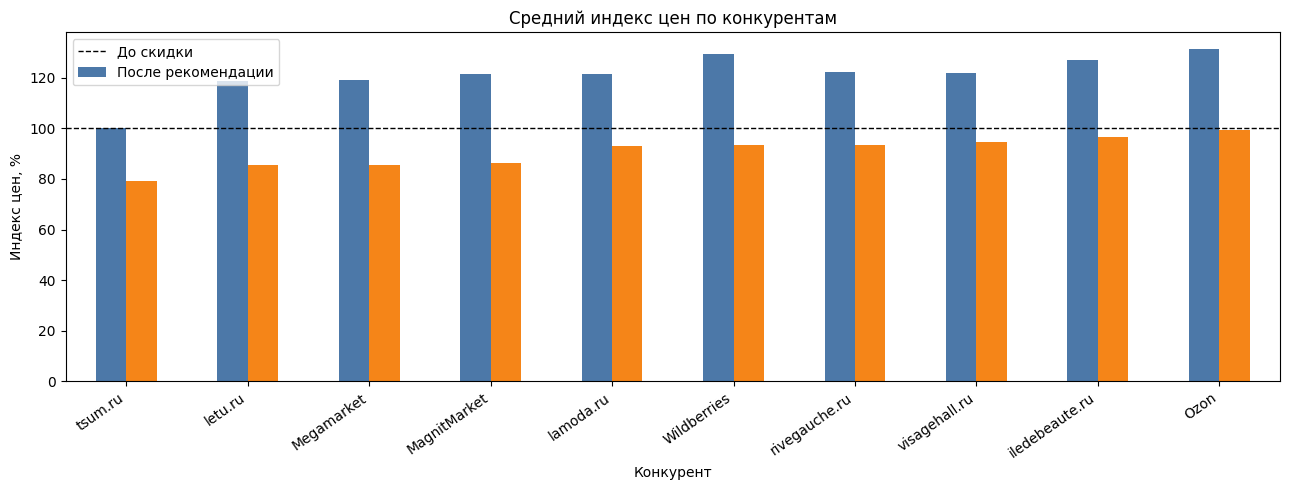

,Статус,Количество SKU
0,Можно конкурировать с рынком при GM не ниже 10%,527
1,"Минимум рынка ниже цены, допустимой при GM 10%",156


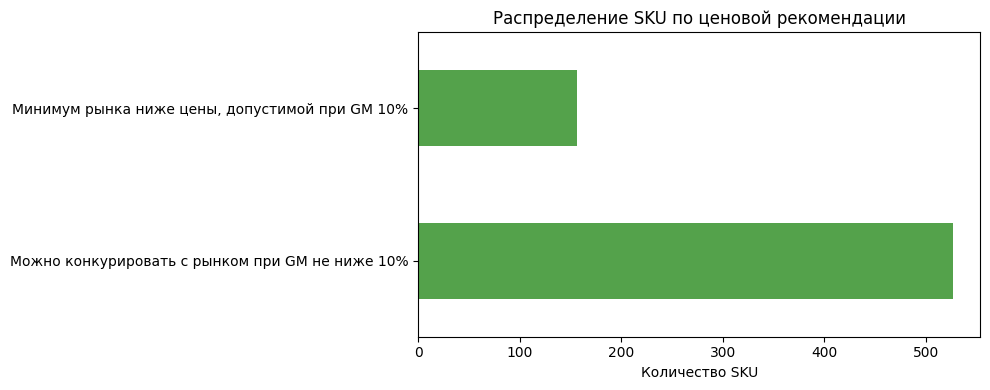

In [22]:
# Графики

plot_data = final_index_summary.set_index("competitor")

ax = plot_data[
    ["index_before_discount", "index_after_recommendation"]
].plot(
    kind="bar",
    figsize=(13, 5),
    color=["#4C78A8", "#F58518"]
)

ax.axhline(100, color="black", linestyle="--", linewidth=1)
ax.set_title("Средний индекс цен по конкурентам")
ax.set_xlabel("Конкурент")
ax.set_ylabel("Индекс цен, %")
ax.legend(["До скидки", "После рекомендации"])
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

status_summary = (
    data["pricing_status"]
    .value_counts()
    .rename_axis("Статус")
    .reset_index(name="Количество SKU")
)

display(status_summary)

ax = status_summary.plot(
    kind="barh",
    x="Статус",
    y="Количество SKU",
    legend=False,
    figsize=(10, 4),
    color="#54A24B"
)

ax.set_title("Распределение SKU по ценовой рекомендации")
ax.set_xlabel("Количество SKU")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Промежуточный вывод: графики
- на первом графике видно, как индекс цен снижается по каждому конкуренту
- на втором — что 527 товаров можно довести до рынка, а 156 нельзя

In [23]:
# Товары, где одновременно выполнить стратегию минимальной цены и требование GM >= 10% нельзя
not_feasible = proposal.loc[proposal["pricing_status"].eq("Минимум рынка ниже цены, допустимой при GM 10%")].copy()

print("SKU, где минимум рынка недостижим при GM >= 10%:", len(not_feasible))
print("SKU с конфликтом активных правил:", int(data["rule_conflict"].sum()))
print("SKU без правила:", int(data["selected_markup"].isna().sum()))
not_feasible.head(20)

SKU, где минимум рынка недостижим при GM >= 10%: 156
SKU с конфликтом активных правил: 0
SKU без правила: 0


,Код товара,Наименование товара,Бренд,Сегмент,Цена закупки товара,priority_name,rule_excel_row,selected_markup,price_before_discount,market_min_price,min_price_gm10,recommended_final_price,recommended_discount_pct,recommended_gm,pricing_status
0,19000412437,CLARINS Тушь д/ресниц Wonder volume xxl 8мл,Clarins,Люкс,983,Бренд,51,1.03,1995.49,1029.0,1092.222222,1092.222222,0.452655,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
1,14037100013,Clarins Флюид тональный устойчивый с омолажива...,Clarins,Люкс,1957,Бренд,51,1.03,3972.71,2107.0,2174.444444,2174.444444,0.452655,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
2,19000033387,CLARINS Масло-блеск для губ Lip Comfort Oil т....,Clarins,Люкс,850,Бренд,51,1.03,1725.5,919.0,944.444444,944.444444,0.452655,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
4,19000168458,Clarins Масло-блеск д/губ Lip Comfort 17 7мл,Clarins,Люкс,835,Бренд,51,1.03,1695.05,924.0,927.777778,927.777778,0.452655,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
3,14037100015,Clarins Флюид тональный устойчивый с омолажива...,Clarins,Люкс,2145,Бренд,51,1.03,4354.35,2355.0,2383.333333,2383.333333,0.452655,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
501,3206300001,Vivienne Sabo Карандаш д/бровей Coup de Genie ...,Vivienne Sabo,Массмаркет,279,Бренд / Категория3,120,0.95,544.05,278.0,310.0,310.000000,0.430199,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
537,3206300003,Vivienne Sabo Карандаш д/бровей Coup de Genie ...,Vivienne Sabo,Массмаркет,124,Бренд / Категория3,120,0.95,241.8,112.0,137.777778,137.777778,0.430199,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
74,19000237886,Vivienne Sabo Карандаш-каял д/глаз гелевый Vir...,Vivienne Sabo,Массмаркет,288,Бренд / Категория3,111,0.85,532.8,304.0,320.0,320.000000,0.399399,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
86,3234600004,Vivienne Sabo Карандаш-каял д/глаз гелевый Vir...,Vivienne Sabo,Массмаркет,307,Бренд / Категория3,111,0.85,567.95,329.0,341.111111,341.111111,0.399399,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"
106,19000042796,Vivienne Sabo Карандаш д/глаз Virtuose automat...,Vivienne Sabo,Массмаркет,234,Бренд / Категория3,111,0.85,432.9,256.0,260.0,260.000000,0.399399,0.1,"Минимум рынка ниже цены, допустимой при GM 10%"


### Промежуточный вывод: товары, где минимум рынка недостижим
- таких товаров 156, из них 151 - Vivienne Sabo (из 241) и только 5 - Clarins (из 442)
- почти все это макияж: помады, блески, карандаши для глаз, тени
- у половины из них цена с маржой 10% выше рынка не больше чем на 17%
- у 98 товаров Vivienne Sabo минимум рынка вообще ниже нашей закупки, и тут скидка не поможет
- для них нужно либо договариваться о закупочной цене, либо не гнаться за минимумом рынка

In [24]:
всего_sku = len(data)
можно_конкурировать = (data["pricing_status"].eq("Можно конкурировать с рынком при GM не ниже 10%").sum())
нельзя_конкурировать = (data["pricing_status"].eq("Минимум рынка ниже цены, допустимой при GM 10%").sum())
главный_конкурент = price_index_summary.loc[price_index_summary["mean_price_index"].idxmax()]

note = f"""
В анализ вошло {всего_sku} товаров.

По {можно_конкурировать} товарам можно выйти на минимальную цену рынка
и сохранить маржинальность не ниже 10%.

По {нельзя_конкурировать} товарам минимальная цена рынка ниже
допустимой цены при маржинальности 10%. Для них не стоит снижать цену
до рынка без пересмотра закупочной цены или наценки.

Самый заметный ценовой разрыв - с конкурентом {главный_конкурент["competitor"]}.
Средний индекс цен составляет {главный_конкурент["mean_price_index"]:.1f}.
Значение выше 100 означает, что наша цена в среднем выше цены конкурента.

Рекомендуется снизить цены только по товарам, где это не нарушает
ограничение по маржинальности. По остальным товарам нужно отдельно
пересмотреть правила наценки.
"""

print(note)


В анализ вошло 683 товаров.

По 527 товарам можно выйти на минимальную цену рынка
и сохранить маржинальность не ниже 10%.

По 156 товарам минимальная цена рынка ниже
допустимой цены при маржинальности 10%. Для них не стоит снижать цену
до рынка без пересмотра закупочной цены или наценки.

Самый заметный ценовой разрыв - с конкурентом Ozon.
Средний индекс цен составляет 131.5.
Значение выше 100 означает, что наша цена в среднем выше цены конкурента.

Рекомендуется снизить цены только по товарам, где это не нарушает
ограничение по маржинальности. По остальным товарам нужно отдельно
пересмотреть правила наценки.



## Итог по заданию 1
- по 527 из 683 товаров можно встать в минимальную цену рынка и сохранить маржу не ниже 10%. Для этого нужна скидка около 20% от цены до скидки
- у Clarins проблем почти нет: наценка 1,03 даёт запас, на 437 из 442 товаров можно уйти в минимум рынка
- у Vivienne Sabo наценка около 0,59 слишком мала для рынка: минимум достижим только на 90 из 241 товаров
- справочник наценок лучше менять точечно: для Vivienne Sabo по категориям (помады, блески, карандаши, тени), а не по всему бренду
- где рынок ниже закупки, наценка не спасёт, возможно потребуется разговор с поставщиком